<a href="https://colab.research.google.com/github/aryan-agrawal-1/dissertation/blob/main/notebooks/Reasoning_QA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 1: Which bits of reasoning help retrieval?

Starting with 3 Biology queries, then expand to 12 queries across Biology, Stack Overflow and TheoremQA. We generate 1 cached response per query, manually label its chunks, and compare edited versions using the same full domain corpus and BM25 retriever.

**Model:** We are using `deepseek-r1-distil-qwen-14b`. ThinkQE uses this checkpoint as its main generator (3.1), so it is a better first choice than choosing a random other model

**Experiment:** original query versus full generated reasoning + answer, truncation, manual removal, and compression. Generated variants replace the original query, following BRIGHT's reasoning-query experiment. This is an ablation pilot, not a reproduction of ThinkQE's multi-round method.


## 1. Install the experiment packages
Put this in the first code cell. Run it once per new runtime. If Colab asks for a restart, restart and continue at step 2. This is a research notebook environment, not a production dependency change.


In [ ]:
%pip -q install \
    "python-terrier==1.0" "pyterrier==1.1.2" \
    "pyterrier-rag==0.3.0" "openai==3.26.0" \
    "transformers==4.51.3" "sentence-transformers==4.1.0" \
    "datasets==3.6.0" "pyarrow==19.0.1" \
    "matplotlib==3.11.2"

## 2. Connect Drive and choose the pilot size
for full run set `DOMAINS = ["biology", "stackoverflow", "theoremqa_theorems"]` and `QUERIES_PER_DOMAIN = 4. Changed config gets its own folder, so it won't reuse a different experiment's annotations.


In [ ]:
import hashlib
import importlib.metadata
import json
import math
import pprint
import random
import re
import shutil
import time
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd
import pyterrier as pt
from google.colab import drive, userdata
from IPython.display import display

drive.mount('/content/drive')
DOMAINS = ['biology']
QUERIES_PER_DOMAIN = 3
SEED = 20
RUN_LABEL = 'pilot_v1'  # just to highlight versions of experiment if we change it
MODEL_ID = 'deepseek-r1-distil-qwen-14b'

BASE_URL = 'http://api.terrier.org/v1'
TOKENIZER_ID = 'deepseek-ai/DeepSeek-R1-Distill-Qwen-14B'
TOKENIZER_REVISION = '1df8507178afcc1bef68cd8c393f61a886323761' # reproducability
DATASET_ID = 'xlangai/BRIGHT'
DATASET_REVISION = '3066d29c9651a576c8aba4832d249807b181ecae' # reproducability
MAX_NEW_TOKENS = 8192  # A ceiling  - not target length
TEMPERATURE = 0.6
TOP_P = 0.95
BM25_CONTROLS = {'bm25.k_1': '1.2', 'bm25.b': '0.75', 'bm25.k_3': '8'}
PROMPT = """{query}

Instructions:
1. Identify the essential problem.
2. Reason through what information could be relevant and helpful to address the question in detail.
3. Draft a candidate answer, explaining the concepts and steps needed.
"""  # Adapted from BRIGHT / ReasonIR

ROOT = Path('/content/drive/MyDrive/diss_reasoning_pilot')
PACKAGES = ['pyterrier', 'python-terrier', 'pyterrier-rag', 'openai', 'datasets', 'transformers', 'matplotlib']
versions = {name: importlib.metadata.version(name) for name in PACKAGES}

config = dict(run_label=RUN_LABEL, domains=DOMAINS, queries_per_domain=QUERIES_PER_DOMAIN, seed=SEED,
              model=MODEL_ID, base_url=BASE_URL, tokenizer=TOKENIZER_ID,
              tokenizer_revision=TOKENIZER_REVISION, dataset=DATASET_ID,
              dataset_revision=DATASET_REVISION, max_new_tokens=MAX_NEW_TOKENS,
              temperature=TEMPERATURE, top_p=TOP_P, prompt=PROMPT,
              query_mode='replace_with_generated_text', bm25_controls=BM25_CONTROLS,
              versions=versions, protocol_version=1)

run_id = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()[:12]
RUN = ROOT / ('run_' + run_id)
RUN.mkdir(parents=True, exist_ok=True)

def save_json(path, value):
    # only replace after writing the whole file
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(json.dumps(value, indent=2, ensure_ascii=False))
    temporary.replace(path)

save_json(RUN / 'config.json', config)
(RUN / 'environment.txt').write_text('\n'.join(f'{name}=={version}' for name, version in versions.items()))
print('Your experiment files will be saved in:', RUN)
print('Package versions:', versions)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Your experiment files will be saved in: /content/drive/MyDrive/diss_reasoning_pilot/run_89489f6d6c57
Package versions: {'pyterrier': '1.1.2', 'python-terrier': '1.0', 'pyterrier-rag': '0.3.0', 'openai': '3.26.0', 'datasets': '3.6.0', 'transformers': '4.51.3', 'matplotlib': '3.11.2'}


## 3. Set up the model and preserve exposed reasoning
We'll use a small subclass of PyTerrier RAG's `OpenAIBackend`. The standard `generate()` keeps `message.content`, which can discard the separately returned `reasoning_content`. This adapter preserves the raw response, reasoning, final answer, usage and finish reason.

We only analyse reasoning the service actually returns. If none is exposed, generation stops with a useful error rather than treating the final answer as a reasoning trace.


In [ ]:
import scipy.sparse.linalg
import pyterrier_rag as ptr
from pyterrier_rag.backend import BackendOutput
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_ID, revision=TOKENIZER_REVISION)

def token_count(text):
    return len(tokenizer.encode(text, add_special_tokens=False))

def split_response(raw):
    choice = raw['choices'][0]
    if choice.get('finish_reason') != 'stop':
        raise ValueError('Response did not finish normally see the saved raw response; ')

    message = choice['message']
    content = message.get('content') or ''
    reasoning = message.get('reasoning_content') or message.get('reasoning') or ''
    source = 'separate_field'

    if not reasoning and '</think>' in content:
        before, content = content.split('</think>', 1)
        reasoning = before.split('<think>', 1)[-1]
        source = 'think_tags'

    if not isinstance(reasoning, str) or not reasoning.strip():
        raise ValueError('No exposed reasoning found. The raw response is saved. ')

    if not content.strip():
        raise ValueError('No final answer returned. Inspect the raw response before continuing.')
    return {'reasoning': reasoning.strip(), 'answer': content.strip(), 'reasoning_source': source,
            'full_text': reasoning.strip() + '\n\n' + content.strip()}

class RecordedReasoningBackend(ptr.OpenAIBackend):
    supports_logprobs = False
    supports_num_responses = False

    def generate(self, inps):
        # make 1 request at a time and save it before parsing anything.
        if not isinstance(inps, list) or not all(isinstance(prompt, str) for prompt in inps):
            raise TypeError('accept a list of text prompts.')

        outputs = []
        self.records = []

        for prompt in inps:
            started = time.perf_counter()
            response = self.client.chat.completions.create(
                model=self.model_id, messages=[{'role': 'user', 'content': prompt}],
                max_tokens=MAX_NEW_TOKENS, temperature=TEMPERATURE, top_p=TOP_P,
                timeout=300.0)
            raw = response.model_dump(mode='json')
            record = {'raw_response': raw, 'elapsed_seconds': time.perf_counter() - started,
                      'prompt': prompt, 'created_utc': datetime.now(timezone.utc).isoformat()}
            save_json(RUN / 'last_response.json', record)
            record.update(split_response(raw))
            self.records.append(record)
            outputs.append(BackendOutput(text=record['full_text']))
        return outputs

backend = RecordedReasoningBackend(MODEL_ID, base_url=BASE_URL,
    api_key=userdata.get('IDA_LLM_API_KEY'), max_new_tokens=MAX_NEW_TOKENS,
    max_input_length=32768, max_retries=2, timeout=300, parallel=1)
print('Backend ready')


/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Backend ready


## 4. Load BRIGHT and freeze the query selection
Download the chosen domains' original examples and passage corpuses. We ignore BRIGHT's human reasoning and gold answers as generator input.


In [ ]:
from datasets import load_dataset
from huggingface_hub import HfApi

repo_files = HfApi().list_repo_files(DATASET_ID, repo_type='dataset', revision=DATASET_REVISION)

def load_bright_part(part, domain):
    paths = sorted(path for path in repo_files
                   if path.startswith(f'{part}/{domain}-') and path.endswith('.parquet'))
    if not paths:
        raise ValueError(f'No {part} found for domain {domain}. Check the domain name.')
    urls = [f'hf://datasets/{DATASET_ID}@{DATASET_REVISION}/{path}' for path in paths]
    return load_dataset('parquet', data_files=urls, split='train')

corpora = {}
selection = []
for domain in DOMAINS:
    examples = load_bright_part('examples', domain)
    corpus = load_bright_part('documents', domain)
    corpora[domain] = corpus
    required = {'id', 'query', 'gold_ids', 'excluded_ids'}
    if not required.issubset(examples.column_names) or not {'id', 'content'}.issubset(corpus.column_names):
        raise ValueError('Unexpected BRIGHT schema. Stop and inspect the dataset.')
    if QUERIES_PER_DOMAIN > len(examples):
        raise ValueError('Requested more queries than this domain contains.')
    positions = sorted(random.Random(SEED).sample(range(len(examples)), QUERIES_PER_DOMAIN))
    doc_ids = set(map(str, corpus['id']))
    if len(doc_ids) != len(corpus):
        raise ValueError('Duplicate corpus document IDs.')
    for position in positions:
        example = examples[position]
        gold = list(map(str, example['gold_ids']))
        excluded = list(map(str, example['excluded_ids']))
        if not gold or not set(gold).issubset(doc_ids) or set(gold) & set(excluded):
            raise ValueError('Invalid relevance labels or document exclusions.')
        selection.append(dict(qid=f"{domain}/{example['id']}", source_id=str(example['id']),
                              domain=domain, query=example['query'], gold_ids=gold,
                              excluded_ids=excluded))
    print(f'{domain}: {len(corpus):,} corpus documents; {len(positions)} selected queries')

selection_path = RUN / 'selection.json'
if selection_path.exists() and json.loads(selection_path.read_text()) != selection:
    raise ValueError('Selection changed within this run. Start a fresh configuration.')
save_json(selection_path, selection)
queries = pd.DataFrame(selection)
display(queries[['qid', 'domain', 'query']])  # Gold documents stay hidden until the manual work is done.


examples/biology-00000-of-00001.parquet:   0%|          | 0.00/201k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

documents/biology-00000-of-00001.parquet:   0%|          | 0.00/11.0M [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

biology: 57,359 corpus documents; 3 selected queries


,qid,domain,query
0,biology/87,biology,Below which temperature human muscles don't wo...
1,biology/92,biology,How fast do we fall asleep?\nWhen looking at t...
2,biology/100,biology,What types of light can't a plant photosynthes...


## 5. Build reusable BM25 indexes
index the full corpus for each domain. The index is built on Colab's local disk, then archived to Drive so a runtime restart doesn't lose it. This is Terrier BM25, with recorded settings.

In [ ]:
# Initialise Java before we create Terrier indexes.
if not pt.java.started():
    pt.java.init()

indexes = {}
retrievers = {}
index_identity = hashlib.sha256(json.dumps(
    {'dataset_revision': DATASET_REVISION, 'pyterrier': versions['pyterrier'],
     'tokeniser': 'EnglishTokeniser', 'termpipelines': 'Stopwords,PorterStemmer'},
    sort_keys=True).encode()).hexdigest()[:12]
index_store = ROOT / 'indexes' / index_identity
index_store.mkdir(parents=True, exist_ok=True)

for domain, corpus in corpora.items():
    local_dir = Path('/content/diss_indexes') / index_identity / domain
    archive = index_store / f'{domain}.tar.gz'
    if not (local_dir / 'data.properties').exists():
        if archive.exists():
            local_dir.mkdir(parents=True, exist_ok=True)
            shutil.unpack_archive(str(archive), str(local_dir))

        else:
            # a partial build gets its own directory; don't reuse an incomplete index.
            build_dir = local_dir.with_name(domain + '_building')
            if build_dir.exists():
                shutil.rmtree(build_dir)  # Only our disposable local build directory.
            build_dir.parent.mkdir(parents=True, exist_ok=True)
            indexer = pt.terrier.IterDictIndexer(str(build_dir),
                meta={'docno': max(len(str(value)) for value in corpus['id'])},
                text_attrs=['text'], threads=1,
                properties={'tokeniser': 'EnglishTokeniser', 'termpipelines': 'Stopwords,PorterStemmer'})
            indexer.index({'docno': str(doc['id']), 'text': doc['content']} for doc in corpus)
            build_dir.rename(local_dir)
            local_archive = shutil.make_archive(str(local_dir), 'gztar', root_dir=local_dir)
            temporary_archive = archive.with_suffix('.tmp')
            shutil.copyfile(local_archive, temporary_archive)
            temporary_archive.replace(archive)

    index = pt.IndexFactory.of(str(local_dir / 'data.properties'))
    assert index.getCollectionStatistics().getNumberOfDocuments() == len(corpus)
    indexes[domain] = index
    exclusions = queries.loc[queries.domain == domain, 'excluded_ids']
    depth = 10 + max(map(len, exclusions))
    # extra candidates ensure exclusions can't leave a short top ten unnecessarily.
    retrievers[domain] = pt.rewrite.tokenise() >> pt.terrier.Retriever(
        index, wmodel='BM25', controls=BM25_CONTROLS, num_results=depth)
print('Indexes ready for:', ', '.join(indexes))


terrier-assemblies 5.11 jar-with-dependencies not found, downloading to /root/.pyterrier...


https://repo1.maven.org/maven2/org/terrier/terrier-assemblies/5.11/terrier-assemblies-5.11-jar-with-dependenci…

Done
terrier-python-helper 0.0.8 jar not found, downloading to /root/.pyterrier...


https://repo1.maven.org/maven2/org/terrier/terrier-python-helper/0.0.8/terrier-python-helper-0.0.8.jar:   0%| …

Done


Java started and loaded: pyterrier.java.colab, pyterrier.java, pyterrier.java.24, pyterrier.terrier.java [version=5.11 (build: craig.macdonald 2025-01-13 21:29), helper_version=0.0.8]


Indexes ready for: biology


## 6. Generate each response once
Responses are saved individually, so rerunning resumes rather than regenerating finished queries. No gold documents, retrieval results or human reference traces are supplied to the model.

If a response is cut off, it is saved as `last_response.json` and this cell stops.


In [ ]:
trace_dir = RUN / 'traces'
trace_dir.mkdir(exist_ok=True)
traces = {}

for row in queries.itertuples():
    filename = hashlib.sha256(row.qid.encode()).hexdigest()[:16] + '.json'
    path = trace_dir / filename
    prompt = PROMPT.format(query=row.query)

    if path.exists():
        record = json.loads(path.read_text())
        if record['prompt'] != prompt or record['qid'] != row.qid:
            raise ValueError('Cached response does not match this query.')
        print('Reusing:', row.qid)
    else:
        print('Generating:', row.qid, flush=True)
        output = backend.generate([prompt])[0]
        record = dict(backend.records[0], qid=row.qid, model_alias=MODEL_ID,
                      tokenizer=TOKENIZER_ID, tokenizer_revision=TOKENIZER_REVISION)
        assert output.text == record['full_text']
        save_json(path, record)

    traces[row.qid] = record
    print('  reasoning tokens:', token_count(record['reasoning']),
          '| answer tokens:', token_count(record['answer']),
          '| source:', record['reasoning_source'])
print('All complete responses saved. Keep these fixed for every ablation.')


Reusing: biology/87
  reasoning tokens: 573 | answer tokens: 274 | source: think_tags
Reusing: biology/92
  reasoning tokens: 943 | answer tokens: 427 | source: think_tags
Reusing: biology/100
  reasoning tokens: 611 | answer tokens: 389 | source: think_tags
All complete responses saved. Keep these fixed for every ablation.


## 7. Make the automatic baselines
The full-trace baseline includes the exposed reasoning and candidate answer, with transport tags removed. We also retain a reasoning-only baseline and an answer-only baseline to make their roles clear. Prefix truncation applies to the same full text at 25%, 50% and 75%.

Token lengths use the pinned model tokenizer as a consistent offline measure. They are not claimed to be exact counts; server usage is kept separately in the raw responses. BM25 consumes lexical terms, not LLM tokens.


In [ ]:
def prefix_at_budget(text, budget):
    # slice at a token boundary in the original string without cutting a Unicode chars.
    encoded = tokenizer(text, add_special_tokens=False, return_offsets_mapping=True)
    offsets = encoded['offset_mapping']
    if budget <= 0:
        return ''
    if budget >= len(offsets):
        return text
    end = offsets[budget - 1][1]
    prefix = text[:end]
    while prefix and token_count(prefix) > budget:
        end -= 1
        prefix = text[:end]
    return prefix

variant_rows = []
def add_variant(qid, variant, text, **extra):
    if not text.strip():
        return  # an empty ablation has no retrieval query not silently scored as zero.
    query_row = queries.set_index('qid').loc[qid]
    variant_rows.append(dict(qid=qid, domain=query_row.domain, variant=variant,
                             text=text, tokens=token_count(text), **extra))

for row in queries.itertuples():
    trace = traces[row.qid]
    full = trace['full_text']
    add_variant(row.qid, 'original', row.query)
    add_variant(row.qid, 'full_trace', full)
    add_variant(row.qid, 'reasoning_only', trace['reasoning'])
    add_variant(row.qid, 'answer_only', trace['answer'])
    for percent in [25, 50, 75]:
        budget = max(1, math.floor(token_count(full) * percent / 100))
        add_variant(row.qid, f'truncate_{percent}', prefix_at_budget(full, budget), target_budget=budget)
print(f'{len(variant_rows)} automatic variants prepared. Scores are held back until after annotation.')


21 automatic variants prepared. Scores are held back until after annotation.


## 8. Optional: rewritten traces
For the first run, leave `REWRITES = []` and continue. This cell prints one full trace; change `READ_QID` to another query ID from step 4 when you want to read a different one. Paste the whole revised text into an entry below. Choose a descriptive name and briefly explain what changed.

```python
REWRITES = [
  {
    "qid": "biology/87",
    "name": "without_candidate_answer",
    "text": """Paste your rewritten trace here.""",
    "change": "Removed the candidate answer; kept the reasoning."
  }

]
```


In [ ]:
# Change this to another selected query ID when you want to read its trace.
READ_QID = queries.iloc[0].qid
print('QUERY:', READ_QID)
print(traces[READ_QID]['full_text'])

# MANUAL, OPTIONAL: paste whole rewritten traces here. No labels needed.
REWRITES = []

rewrite_path = RUN / 'rewrites.json'
saved = json.loads(rewrite_path.read_text()) if rewrite_path.exists() else []
rewrites = {(item['qid'], item['name']): item for item in saved}
for item in REWRITES:
    if item['qid'] not in traces:
        raise ValueError(f"Unknown query: {item['qid']}")
    if not item['name'].strip() or not item['text'].strip():
        raise ValueError('Give each rewrite a name and non-empty text.')
    rewrites[(item['qid'], item['name'])] = dict(item, change=item.get('change', ''))
save_json(rewrite_path, list(rewrites.values()))

# Rebuild from the fixed automatic baselines so rerunning doesn't duplicate rows.
automatic_names = {'original', 'full_trace', 'truncate_25', 'truncate_50', 'truncate_75'}
variant_rows = [row for row in variant_rows if row['variant'] in automatic_names]
for (qid, name), item in rewrites.items():
    add_variant(qid, 'rewrite:' + name, item['text'], change=item['change'])
    budget = token_count(item['text'])
    prefix = prefix_at_budget(traces[qid]['full_text'], budget)
    add_variant(qid, 'matched_prefix:' + name, prefix,
                change='First tokens of the full trace, matched to rewrite length.')
variants = pd.DataFrame(variant_rows)
if variants.duplicated(['qid', 'variant']).any():
    raise ValueError('Duplicate query/variant rows. Rerun step 7, then this step.')
variants.to_csv(RUN / 'variants.csv', index=False)
print(f'{len(variants)} variants ready, including {len(rewrites)} saved rewrites.')

QUERY: biology/87
Okay, so I'm trying to figure out the temperature at which human muscles stop working properly. From what I understand, when it's really cold, especially in places like hands and feet, muscles can get numb and stop moving. But I'm not exactly sure what temperature threshold triggers this.

First, I know that the human body has an optimal temperature, which is around 98.6°F or 37°C. This is the core body temperature, and it's regulated by the body to maintain various functions. But how does this relate to muscle function?

I remember that muscles require energy to contract, and that energy comes from chemical reactions which are enzyme-dependent. Enzymes work best within a specific temperature range. If the temperature drops too low, enzymes might not function properly, which would slow down muscle contractions. But I'm not sure what exact temperature that happens at.

I also recall that muscles can become fatigued or stiff in the cold, which might be due to reduced bl


## 9. Retrieve and evaluate every variant with PyTerrier
BRIGHT's `excluded_ids` are removed **before** choosing the top ten. We retrieve enough extra candidates to refill those positions. Relevance is binary (`gold_ids`), and nDCG@10 is reported on a 0–1 scale.

The qrels always belong to the original question, even when we edit its retrieval text. Queries with no hits get 0. Ties are resolved by document ID for reproducibility. Rankings and per-query scores are saved.

Run this before doing any manual editing to get your automatic baseline results. Rerun it after step 8 whenever you add a rewrite.

In [ ]:
from pyterrier.measures import nDCG

qrels = pd.DataFrame([{'qid': row.qid, 'docno': docno, 'label': 1}
                      for row in queries.itertuples() for docno in row.gold_ids])
excluded_by_qid = {row.qid: set(row.excluded_ids) for row in queries.itertuples()}

def eligible_top_ten(results):
    results = results.copy()
    if results.empty:
        return results
    results['qid'] = results.qid.astype(str)
    results['docno'] = results.docno.astype(str)
    keep = [docno not in excluded_by_qid[qid] for qid, docno in zip(results.qid, results.docno)]
    results = results.loc[keep].sort_values(['qid', 'score', 'docno'], ascending=[True, False, True])
    results = results.groupby('qid', sort=False).head(10).copy()
    results['rank'] = results.groupby('qid', sort=False).cumcount()
    return results

runs = []
score_rows = []
for variant, variant_group in variants.groupby('variant', sort=False):
    variant_runs = []
    for domain, group in variant_group.groupby('domain', sort=False):
        topics = group[['qid', 'text']].rename(columns={'text': 'query'})
        variant_runs.append(eligible_top_ten(retrievers[domain].transform(topics)))
    run = pd.concat(variant_runs, ignore_index=True)
    relevant_qrels = qrels[qrels.qid.isin(variant_group.qid)]
    scores = pt.Evaluate(run, relevant_qrels, metrics=[nDCG@10], perquery=True)
    for qid in variant_group.qid:
        score_rows.append({'qid': qid, 'variant': variant,
                           'ndcg_at_10': scores.get(qid, {}).get('nDCG@10', 0.0)})
    run['variant'] = variant
    runs.append(run)
results = variants.merge(pd.DataFrame(score_rows), on=['qid', 'variant'], validate='one_to_one')
original_scores = results[results.variant == 'original'].set_index('qid').ndcg_at_10
results['delta_vs_original'] = results.ndcg_at_10 - results.qid.map(original_scores)
results.to_csv(RUN / 'results.csv', index=False)
rankings = pd.concat(runs, ignore_index=True)
rankings[['qid', 'variant', 'docno', 'rank', 'score']].to_csv(RUN / 'rankings.csv', index=False)
display(results[['qid', 'variant', 'tokens', 'ndcg_at_10', 'delta_vs_original']])

,qid,variant,tokens,ndcg_at_10,delta_vs_original
0,biology/87,original,91,0.000000,0.000000
1,biology/87,full_trace,847,0.386853,0.386853
2,biology/87,truncate_25,211,0.237198,0.237198
3,biology/87,truncate_50,423,0.386853,0.386853
4,biology/87,truncate_75,635,0.386853,0.386853
5,biology/92,original,144,0.000000,0.000000
6,biology/92,full_trace,1370,0.000000,0.000000
7,biology/92,truncate_25,342,0.000000,0.000000
8,biology/92,truncate_50,685,0.000000,0.000000
9,biology/92,truncate_75,1027,0.000000,0.000000


In [ ]:
# show where the labelled relevant documents appear in each top ten
for qid in ["biology/87", "biology/92", "biology/100"]:
    gold = set(queries.set_index("qid").loc[qid, "gold_ids"])
    print(f"\n{qid}: {len(gold)} labelled relevant documents")

    for variant, group in rankings[rankings.qid == qid].groupby(
        "variant", sort=False
    ):
        hits = group[group.docno.isin(gold)].sort_values("rank")
        positions = (hits["rank"] + 1).tolist()
        print(f"  {variant}: relevant ranks {positions}")


biology/87: 2 labelled relevant documents
  original: relevant ranks []
  full_trace: relevant ranks [2]
  truncate_25: relevant ranks [5]
  truncate_50: relevant ranks [2]
  truncate_75: relevant ranks [2]

biology/92: 2 labelled relevant documents
  original: relevant ranks []
  full_trace: relevant ranks []
  truncate_25: relevant ranks []
  truncate_50: relevant ranks []
  truncate_75: relevant ranks []

biology/100: 2 labelled relevant documents
  original: relevant ranks [2]
  full_trace: relevant ranks [2]
  truncate_25: relevant ranks [2]
  truncate_50: relevant ranks [2]
  truncate_75: relevant ranks [2]


## 10. Plot length versus performance

The plot marks the Pareto frontier: points for which no other variant uses at most as many tokens and achieves at least as good a score, with one improvement. You can focus on whether the shortened variants retain the full trace's performance.

If you added rewrites, the paired table compares each one with a plain prefix at approximately the same actual length. The cost axis is retrieval-input length: editing a cached response does not reduce its original generation cost.

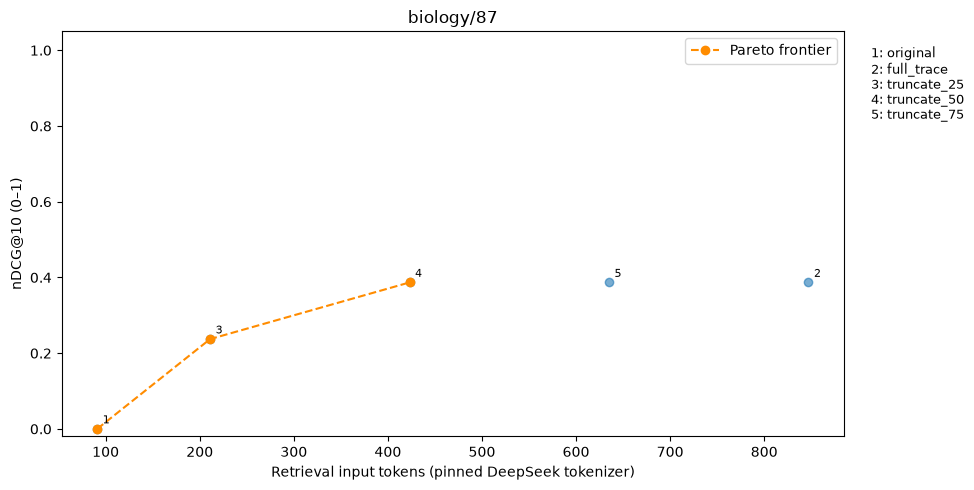

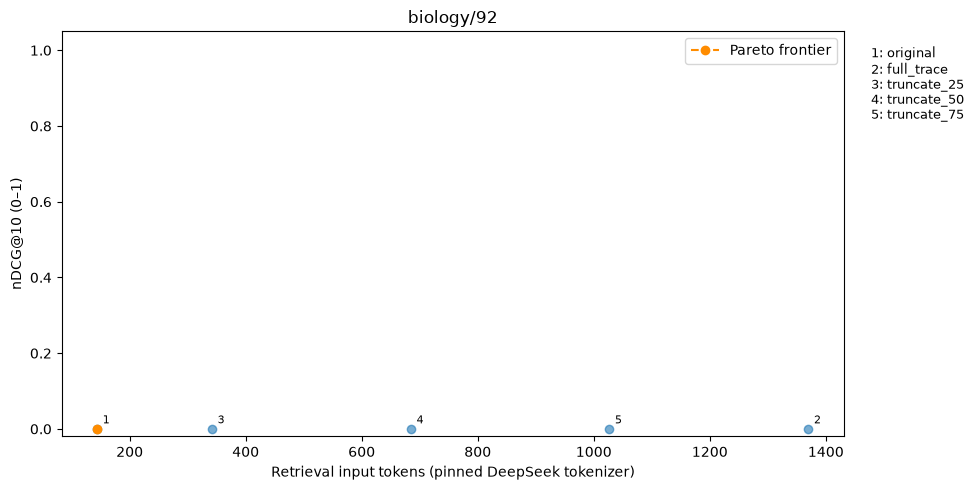

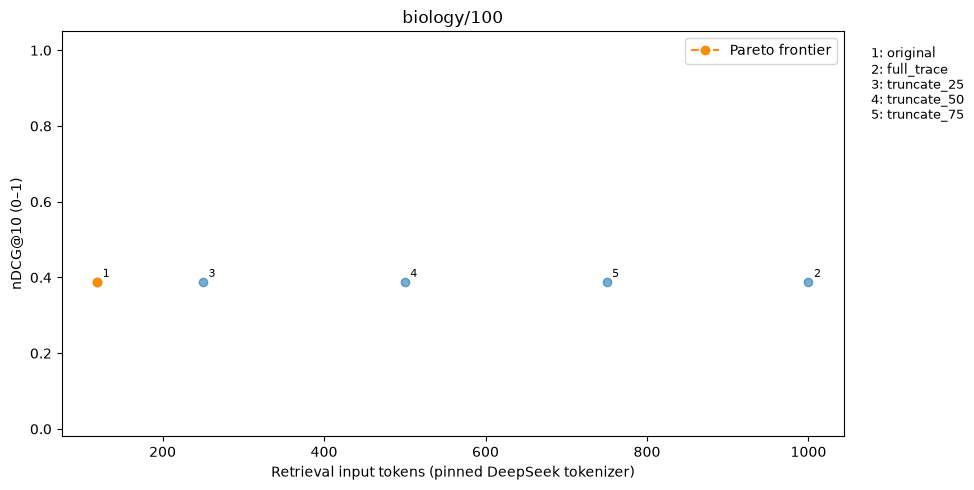

Automatic results plotted. Add a rewrite in step 8 whenever you want to test a specific change.


In [ ]:
import matplotlib.pyplot as plt

def pareto_flags(group):
    return [not any((other.tokens <= row.tokens and other.ndcg_at_10 >= row.ndcg_at_10)
                    and (other.tokens < row.tokens or other.ndcg_at_10 > row.ndcg_at_10)
                    for other in group.itertuples()) for row in group.itertuples()]

results['pareto_optimal'] = False
for qid, group in results.groupby('qid', sort=False):
    results.loc[group.index, 'pareto_optimal'] = pareto_flags(group)
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.scatter(group.tokens, group.ndcg_at_10, alpha=0.6)
    frontier = results.loc[group.index][results.loc[group.index, 'pareto_optimal']].sort_values('tokens')
    ax.plot(frontier.tokens, frontier.ndcg_at_10, 'o--', color='darkorange', label='Pareto frontier')
    # Numbers keep long variant names from covering the points.
    labelled = group.reset_index(drop=True).copy()
    labelled['point_number'] = range(1, len(labelled) + 1)
    for (tokens, score), points in labelled.groupby(['tokens', 'ndcg_at_10']):
        label = ','.join(map(str, points.point_number))
        ax.annotate(label, (tokens, score), fontsize=8,
                    xytext=(4, 4), textcoords='offset points')
    key = '\n'.join(f'{row.point_number}: {row.variant}' for row in labelled.itertuples())
    fig.text(0.73, 0.90, key, va='top', fontsize=9)
    ax.set(xlabel='Retrieval input tokens (pinned DeepSeek tokenizer)', ylabel='nDCG@10 (0–1)',
           title=qid, ylim=(-0.02, 1.05))
    ax.legend()
    fig.tight_layout(rect=[0, 0, 0.72, 1])
    filename = hashlib.sha256(qid.encode()).hexdigest()[:16] + '.png'
    fig.savefig(RUN / filename, dpi=180)
    plt.show()
    plt.close(fig)

pair_rows = []
for qid, group in results.groupby('qid', sort=False):
    lookup = group.set_index('variant')
    for variant in lookup.index:
        if not variant.startswith('rewrite:'):
            continue
        name = variant.split(':', 1)[1]
        rewrite, prefix = lookup.loc[variant], lookup.loc['matched_prefix:' + name]
        pair_rows.append(dict(qid=qid, rewrite=name, rewrite_tokens=int(rewrite.tokens),
            prefix_tokens=int(prefix.tokens), rewrite_ndcg=rewrite.ndcg_at_10,
            prefix_ndcg=prefix.ndcg_at_10, delta=rewrite.ndcg_at_10-prefix.ndcg_at_10))
pairs = pd.DataFrame(pair_rows, columns=['qid', 'rewrite', 'rewrite_tokens', 'prefix_tokens',
                                      'rewrite_ndcg', 'prefix_ndcg', 'delta'])
pairs.to_csv(RUN / 'rewrite_vs_prefix.csv', index=False)
results.to_csv(RUN / 'results.csv', index=False)
if not pairs.empty:
    display(pairs)
else:
    print('Automatic results plotted. Add a rewrite in step 8 whenever you want to test a specific change.')



## 11. Optional: inspect relevant documents and failure cases
Choose a query and variant below to see the source passage text. Look for cases where reasoning helps, hurts, or can be removed. If you use these passages to write a new retrieval query, record that it was informed by gold documents in your change note.


In [ ]:
# MANUAL: change these to an interesting query and variant from the results table.
INSPECT_QID = queries.iloc[0].qid
INSPECT_VARIANT = 'full_trace'

selected = queries.set_index('qid').loc[INSPECT_QID]
lookup = {str(doc['id']): doc['content'] for doc in corpora[selected.domain]}
print('ORIGINAL QUESTION:\n', selected.query)
print('\nRELEVANT PASSAGES:')
for docno in selected.gold_ids:
    print('\n', docno, '\n', lookup[docno])
print('\nTOP TEN FOR:', INSPECT_VARIANT)
subset = rankings[(rankings.qid == INSPECT_QID) & (rankings.variant == INSPECT_VARIANT)]
for row in subset.itertuples():
    print(f'\nRank {row.rank + 1} | {row.docno} | relevant: {row.docno in selected.gold_ids}')
    print(lookup[row.docno])

ORIGINAL QUESTION:
 Below which temperature human muscles don't work?
When one exposes theirs body parts to cold environment (especially foot and hands), they may be numb, with temporarily blocked both muscles.
What is typical body temperature below which human muscles don't work properly?
Moreover, what is the mechanism behind it?
EDIT:
Interested in case when muscles almost cease to work (e.g one is not able to grasp a cup), not just in small perturbations to strength.

RELEVANT PASSAGES:

 below_temperature_muscles_not_work/Shivering_0.txt 
 Shivering (also called shuddering) is a bodily function in response to cold and extreme fear in warm-blooded animals. When the core body temperature drops, the shivering reflex is triggered to maintain homeostasis. Skeletal muscles begin to shake in small movements, creating warmth by expending energy. Shivering can also be a response to fever, as a person may feel cold. During fever, the hypothalamic set point for temperature is raised. The inc

## 12. write the findings here

- **What I ran:** domains, query IDs, model alias, prompt, tokenizer, BM25 settings and run folder.
- **Useful content:** which labels seem helpful, on which queries, and what ablation changed.
- **Compression versus prefix:** compare the matched pairs and note any actual token-count differences.
- **Failure cases:** a case where reasoning helps, one where it harms, and one where compression retains performance.
- **Answering versus retrieval:** examples of chunks that help one, both, or neither.
- **Hypotheses for the next experiment:** 5–10 testable statements, not general conclusions from this sample.
- **Limits:** hand-selected content, one model, one retriever, small sample, and cached-generation cost.

Rerun the setup with four queries in 3 domains (12 total). Complete all three manual compression budgets and annotate every generated chunk. Extend to dense retrieval only after the BM25 comparisons are sound.

- Find examples of similar/duplicate sentences before using MMR
- MMR measurement (https://dl.acm.org/doi/pdf/10.1145/290941.291025)
- Sentence splitter
- Summarising outputs